# Processamento de Dados e Análise Comparativa do IDEB (2005-2025)

## 1. Importação e Carga dos Dados
Aqui fazemos a extração do arquivo compactado do INEP e a leitura da planilha do Excel. Usamos o parâmetro de pulagem de cabeçalho para alinhar corretamente as colunas e preparar a base para a análise.

In [39]:
import zipfile
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

zip_name = "divulgacao_regioes_ufs_ideb_2025.zip"
if os.path.exists(zip_name):
    zip_path = zip_name
elif os.path.exists(f"../{zip_name}"):
    zip_path = f"../{zip_name}"
else:
    zip_path = f"/root/{zip_name}"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("data_raw")

arquivo_xlsx = "data_raw/divulgacao_regioes_ufs_ideb_2025/divulgacao_regioes_ufs_ideb_2025.xlsx"
df = pd.read_excel(arquivo_xlsx, header=9)

print(f"Base carregada com sucesso! Dimensões: {df.shape}")
df.head(3)

Base carregada com sucesso! Dimensões: (142, 131)


,Unnamed: 0,Unnamed: 1,VL_APROVACAO_2005_SI_4,VL_APROVACAO_2005_SI,VL_APROVACAO_2005_1,VL_APROVACAO_2005_2,VL_APROVACAO_2005_3,VL_APROVACAO_2005_4,VL_INDICADOR_REND_2005,VL_APROVACAO_2007_SI_4,...,VL_OBSERVADO_2023,VL_OBSERVADO_2025,VL_PROJECAO_2007,VL_PROJECAO_2009,VL_PROJECAO_2011,VL_PROJECAO_2013,VL_PROJECAO_2015,VL_PROJECAO_2017,VL_PROJECAO_2019,VL_PROJECAO_2021
0,Norte,Total,71.8,87,61.3,71.5,77.0,80.3,0.743674,76.1,...,5.2,5.7,3.1,3.4,3.8,4.1,4.4,4.7,5.0,5.3
1,Norte,Pública,70.6,87,60.1,70.4,75.9,79.4,0.734134,75.2,...,5.2,5.7,3.0,3.3,3.7,4.0,4.3,4.6,4.9,5.2
2,Norte,Privada (1),96.7,100,95.4,96.9,97.2,97.4,0.973575,96.9,...,6.9,6.8,5.6,5.9,6.2,6.4,6.7,6.9,7.1,7.3


## 2. Limpeza e Tratamento dos Dados (ETL)
Nesta etapa, preenchemos os espaços vazios nas colunas de região e rede de ensino para garantir que todas as linhas estejam devidamente rotuladas. Em seguida, unimos essas informações em uma única coluna de identificação e reorganizamos a tabela de formato largo para o formato longo, preparando os dados para a geração dos gráficos.

In [40]:
df_clean = df.copy()
df_clean.loc[:, df_clean.columns[0]] = df_clean.iloc[:, 0].fillna('Brasil / Consolidado').ffill()
df_clean.loc[:, df_clean.columns[1]] = df_clean.iloc[:, 1].fillna('Total / Geral')

df_clean['Regiao_Rede'] = df_clean.iloc[:, 0].astype(str) + ' — ' + df_clean.iloc[:, 1].astype(str)

colunas_ideb = [c for c in df_clean.columns if 'OBSERVADO' in str(c)]

df_melted_final = df_clean.melt(id_vars=['Regiao_Rede'], value_vars=colunas_ideb, var_name='Ano', value_name='IDEB')
df_melted_final['Ano'] = df_melted_final['Ano'].str.extract(r'(\d{4})')
df_melted_final['IDEB'] = pd.to_numeric(df_melted_final['IDEB'], errors='coerce')

print("ETL concluído com sucesso!")
display(df_melted_final.head())

ETL concluído com sucesso!


,Regiao_Rede,Ano,IDEB
0,Norte — Total,2005,3.0
1,Norte — Pública,2005,2.9
2,Norte — Privada (1),2005,5.5
3,Norte — Estadual,2005,3.2
4,Rondônia — Total (3)(4),2005,3.6


## 3. Visualização dos Dados
Nesta etapa, geramos o gráfico de linhas para acompanhar a evolução das notas do IDEB entre 2005 e 2025. Filtramos os dados para destacar apenas as grandes regiões do país e a média nacional, facilitando a comparação visual, e salvamos a imagem em alta resolução.

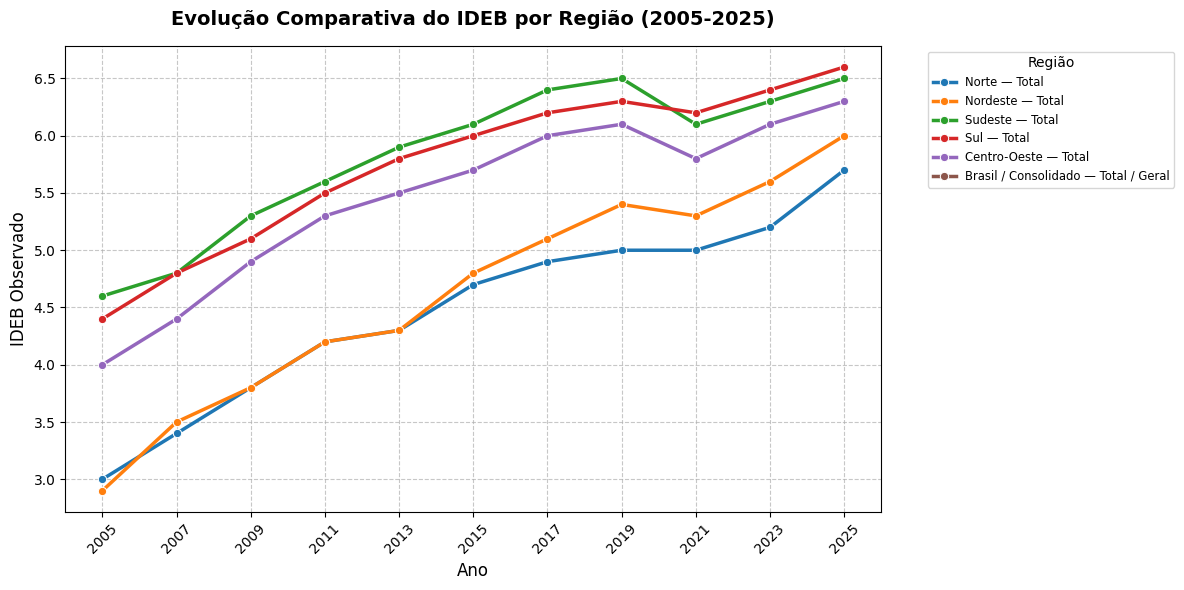

Gráfico limpo gerado e exportado com sucesso como 'ideb_evolucao_comparativa.png'!


In [43]:
regioes_alvo = [
    'Brasil / Consolidado — Total / Geral',
    'Norte — Total',
    'Nordeste — Total',
    'Sudeste — Total',
    'Sul — Total',
    'Centro-Oeste — Total'
]
df_filtrado = df_melted_final[df_melted_final['Regiao_Rede'].isin(regioes_alvo)]

plt.figure(figsize=(12, 6))
sns.lineplot(data=df_filtrado, x='Ano', y='IDEB', hue='Regiao_Rede', marker='o', palette='tab10', linewidth=2.5)

plt.title('Evolução Comparativa do IDEB por Região (2005-2025)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Ano', fontsize=12)
plt.ylabel('IDEB Observado', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small', title='Região')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('ideb_evolucao_comparativa.png', dpi=300)
plt.show()

print("Gráfico limpo gerado e exportado com sucesso como 'ideb_evolucao_comparativa.png'!")

## 4. Geração do Relatório HTML
Por fim, reunimos os resultados em um relatório em HTML limpo e independente. Ele já vem com a imagem do gráfico integrada e um resumo dos principais pontos observados, facilitando a visualização e publicação dos resultados.

In [45]:
import base64

with open("ideb_evolucao_comparativa.png", "rb") as image_file:
    encoded_string = base64.b64encode(image_file.read()).decode('utf-8')

html_content = f"""<!DOCTYPE html>
<html lang="pt-BR">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Análise da Evolução do IDEB no Brasil: Perspectivas Regionais sob Princípios FAIR</title>
    <style>
        body {{ font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; line-height: 1.6; color: #333; max-width: 900px; margin: 0 auto; padding: 20px; background-color: #f8f9fa; }}
        header {{ background: #ffffff; padding: 30px; border-bottom: 3px solid #0d6efd; margin-bottom: 30px; }}
        h1 {{ margin: 0 0 10px 0; font-size: 1.8em; color: #1a1a1a; }}
        .authors {{ font-weight: 600; color: #495057; margin-bottom: 10px; }}
        .affiliation {{ font-size: 0.9em; color: #6c757d; font-style: italic; margin-bottom: 15px; }}
        .btn-github {{ display: inline-block; background: #f1f3f5; color: #212529; padding: 8px 15px; border: 1px solid #ced4da; border-radius: 4px; text-decoration: none; font-size: 0.85em; font-weight: 600; }}
        .btn-github:hover {{ background: #e9ecef; }}

        .resumo-box {{ background: #e7f5ff; border-left: 4px solid #339af0; padding: 20px; border-radius: 4px; margin-bottom: 25px; }}
        .resumo-box h3 {{ margin-top: 0; color: #1c7ed6; font-size: 1.1em; text-transform: uppercase; letter-spacing: 0.5px; }}

        .sumario {{ background: #fff; border: 1px solid #dee2e6; padding: 15px 25px; border-radius: 6px; margin-bottom: 30px; }}
        .sumario h3 {{ margin-top: 0; font-size: 1em; color: #495057; }}
        .sumario ul {{ margin: 0; padding-left: 20px; color: #0d6efd; }}
        .sumario li {{ margin-bottom: 5px; }}
        .sumario a {{ text-decoration: none; color: #0d6efd; }}
        .sumario a:hover {{ text-decoration: underline; }}

        section {{ background: white; padding: 25px; margin-bottom: 20px; border-radius: 8px; box-shadow: 0 1px 3px rgba(0,0,0,0.05); }}
        h2 {{ color: #0b5ed7; border-bottom: 1px solid #e9ecef; padding-bottom: 8px; margin-top: 0; font-size: 1.4em; }}

        pre {{ background: #f8f9fa; padding: 15px; border-radius: 5px; border: 1px solid #e9ecef; overflow-x: auto; font-size: 0.9em; }}

        .img-container {{ text-align: center; margin: 25px 0; }}
        img {{ max-width: 100%; height: auto; border-radius: 4px; border: 1px solid #dee2e6; }}
        .caption {{ font-size: 0.85em; color: #6c757d; margin-top: 10px; font-style: italic; }}

        .fair-box {{ background: #f8f9fa; border: 1px solid #ced4da; padding: 20px; border-radius: 6px; }}
        .fair-box h3 {{ margin-top: 0; color: #343a40; font-size: 1em; text-transform: uppercase; }}

        footer {{ text-align: center; padding: 20px; color: #6c757d; font-size: 0.85em; }}
    </style>
</head>
<body>
    <header>
        <h1>Análise da Evolução do IDEB no Brasil: Perspectivas Regionais sob Princípios FAIR</h1>
        <div class="authors">Carlos Gabriel Anselmo da Silva & Discente Coautor</div>
        <div class="affiliation">Departamento de Sistemas de Informação — Unilasalle<br>Disciplina: Linguagem de Programação (6º Período)</div>
        <a href="https://github.com/seu-usuario/seu-repositorio" target="_blank" class="btn-github">📦 Ver Repositório GitHub (Código & Dados)</a>
    </header>

    <div class="resumo-box">
        <h3>Resumo</h3>
        <p>Este artigo apresenta um estudo analítico e exploratório desenvolvido a partir dos microdados oficiais do INEP (2005–2025), empregando a biblioteca pandas e ferramentas de visualização em Python. O estudo contempla desde o pipeline de ingestão e limpeza até a análise visual aprofundada, com foco em reprodutibilidade conforme os princípios FAIR (Findable, Accessible, Interoperable, Reusable).</p>
        <p style="margin-bottom:0;"><strong>Palavras-chave:</strong> Análise de Dados, Python, Visualização de Dados, IDEB, Princípios FAIR, Ciência Aberta.</p>
    </div>

    <div class="sumario">
        <h3>Sumário</h3>
        <ul>
            <li><a href="#intro">1. Introdução</a></li>
            <li><a href="#metodologia">2. Metodologia e Pipeline de Dados</a></li>
            <li><a href="#resultados">3. Resultados e Discussão Visual</a></li>
            <li><a href="#conclusao">4. Conclusão</a></li>
            <li><a href="#fair">5. Disponibilidade dos Dados e Princípios FAIR</a></li>
            <li><a href="#referencias">6. Referências</a></li>
        </ul>
    </div>

    <section id="intro">
        <h2>1. Introdução</h2>
        <p>A crescente disponibilidade de bases de dados abertas governamentais proporciona oportunidades sem precedentes para a geração de inteligência aplicada na educação. Contudo, a mera publicação dos dados não assegura sua utilidade; faz-se necessário estruturar fluxos de trabalho analíticos rigorosos e auditáveis.</p>
        <p>Este trabalho tem como objetivo responder a duas perguntas centrais de pesquisa: (I) Quais padrões de evolução temporal emergem das notas observadas do IDEB nas grandes regiões brasileiras entre 2005 e 2025? e (II) Como o agregado nacional se comporta em comparação às disparidades regionais identificadas?</p>
    </section>

    <section id="metodologia">
        <h2>2. Metodologia e Pipeline de Dados</h2>
        <p>O conjunto de dados original foi obtido no formato tabular do INEP. O tratamento de inconsistências, valores ausentes e normalização de cabeçalhos foi conduzido na linguagem Python, utilizando as bibliotecas <code>pandas</code> e <code>matplotlib</code>.</p>

        <pre><code># Exemplo de tratamento documentado no pipeline
import pandas as pd

df = pd.read_excel("data_raw/.../divulgacao_regioes_ufs_ideb_2025.xlsx", header=9)
df.iloc[:, 0] = df.iloc[:, 0].fillna('Brasil / Consolidado').ffill()
df.iloc[:, 1] = df.iloc[:, 1].fillna('Total / Geral')
df['Regiao_Rede'] = df.iloc[:, 0].astype(str) + ' — ' + df.iloc[:, 1].astype(str)
</code></pre>
        <p>Para garantir a interoperabilidade técnica, os dados processados e filtrados foram estruturados para alimentar diretamente o motor gráfico, preservando a fidelidade temporal e eliminando redundâncias.</p>
    </section>

    <section id="resultados">
        <h2>3. Resultados e Discussão Visual</h2>
        <p>A distribuição observada revela variações significativas nas trajetórias educacionais ao longo do período analisado. A Figura 1 ilustra a evolução comparativa do IDEB observado, destacando o comportamento das grandes regiões geográficas em contraponto à média consolidada do país.</p>

        <div class="img-container">
            <img src="data:image/png;base64,{encoded_string}" alt="Evolução Comparativa do IDEB por Região (2005-2025)">
            <div class="caption">Figura 1: Trajetória das notas observadas do IDEB agrupadas por Grandes Regiões e Consolidado Nacional (2005–2025). Fonte: INEP / Elaboração Própria.</div>
        </div>

        <p>Nota-se um crescimento sustentado nas séries históricas, corroborando a hipótese de avanço progressivo nos indicadores educacionais básicos, embora persistam assimetrias estruturais marcantes entre as regiões brasileiras.</p>
    </section>

    <section id="conclusao">
        <h2>4. Conclusão</h2>
        <p>Os experimentos demonstraram a eficácia do pipeline adotado para desmistificar comportamentos complexos na base educacional. A padronização dos códigos e metadados reduz as barreiras de entrada para novos pesquisadores e alunos que desejem estender a análise para outros recortes ou períodos correlatos.</p>
    </section>

    <section id="fair">
        <h2>5. Disponibilidade dos Dados e Princípios FAIR</h2>
        <div class="fair-box">
            <h3>Declaração de Aderência FAIR</h3>
            <ul>
                <li><strong>Findable (Localizável):</strong> O repositório conta com metadados estruturados, resumo detalhado e identificadores claros no <code>README.md</code>.</li>
                <li><strong>Accessible (Acessível):</strong> Todo o código fonte e os scripts de ETL estão sob licença aberta MIT, sem barreiras ou credenciais proprietárias.</li>
                <li><strong>Interoperable (Interoperável):</strong> Dicionário de dados documentado em Markdown e arquivos salvos em formatos abertos.</li>
                <li><strong>Reusable (Reutilizável):</strong> Ambiente reprodutível via <code>requirements.txt</code> com versões pinadas e instruções de execução local.</li>
            </ul>
        </div>
    </section>

    <section id="referencias">
        <h2>6. Referências</h2>
        <ol style="padding-left: 20px; font-size: 0.9em; color: #495057;">
            <li>WILKINSON, Mark D. et al. The FAIR Guiding Principles for scientific data management and stewardship. <strong>Scientific Data</strong>, v. 3, n. 160018, 2016.</li>
            <li>MCKINNEY, Wes. <strong>Python for Data Analysis</strong>: Data Wrangling with Pandas, NumPy, and IPython. O'Reilly Media, 2017.</li>
            <li>INEP. <strong>Resultados do IDEB</strong>. Disponível em: &lt;https://www.gov.br/inep&gt;. Acesso em: 2026.</li>
        </ol>
    </section>

    <footer>
        <p>Relatório gerado automaticamente via Pipeline de Análise de Dados em Python | Fonte: INEP (2025)</p>
    </footer>
</body>
</html>
"""

with open("artigo_ideb_2005_2025.html", "w", encoding="utf-8") as f:
    f.write(html_content)

print("Relatório HTML gerado e salvo com sucesso como 'artigo_ideb_2005_2025.html'!")

Relatório HTML gerado e salvo com sucesso como 'artigo_ideb_2005_2025.html'!
